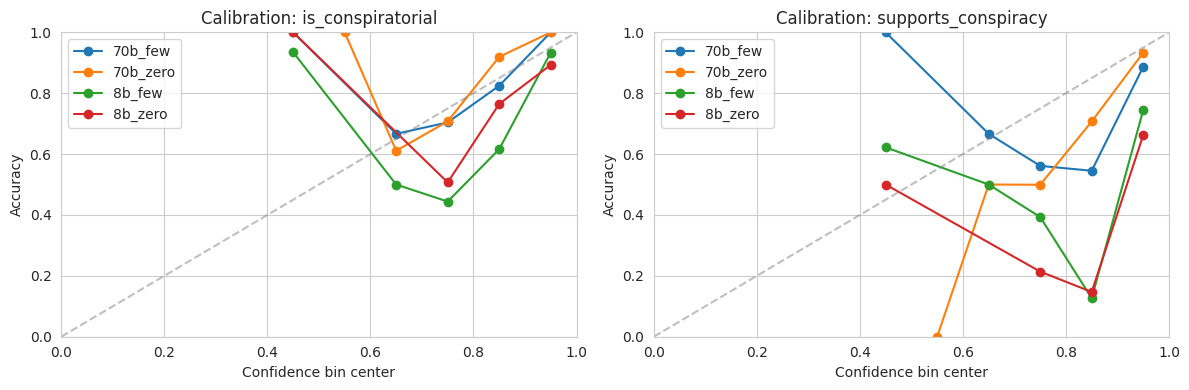

# LLM Annotation Comparative Analysis

This notebook compares results across four experiments:
- 8B Zero-shot
- 8B Few-shot
- 70B Zero-shot
- 70B Few-shot

We compute basic metrics, agreement rates, and visualize distributions.


In [ ]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use project-relative paths
BASE = Path('..').resolve().parent if (Path('.').resolve().name == 'Notebooks') else Path('.')
OUT = BASE / 'outputs'

files = {
    '8b_zero': OUT / 'llama8b-zeroshot_all_classifications_with_llm.csv',
    '8b_few': OUT / 'llama8b-fewshot_all_classifications_with_llm.csv',
    '70b_zero': OUT / 'llama-3.3-70B-zeroshot_all_classifications_with_llm.csv',
    '70b_few': OUT / 'llama-3.3-70B-fewshot_all_classifications_with_llm.csv',
}

missing = [k for k,p in files.items() if not p.exists()]
if missing:
    print('Missing files:', missing)

# Load CSVs
experiments = {}
for key, path in files.items():
    df = pd.read_csv(path)
    # Ensure row_index exists; if not, create from index
    if 'row_index' not in df.columns:
        df['row_index'] = np.arange(len(df))
    # Normalize boolean-ish columns
    for col in ['is_conspiratorial', 'supports_conspiracy']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.lower().map({'true': True, 'false': False}).fillna(df[col])
    experiments[key] = df

for key, df in experiments.items():
    print(f"{key}: {len(df):,} rows, columns={list(df.columns)}")

# Minimal schema check
required_cols = {'row_index','text_id','is_conspiratorial','supports_conspiracy'}
for key, df in experiments.items():
    missing_cols = required_cols - set(df.columns)
    if missing_cols:
        print(f"WARNING: {key} missing columns: {missing_cols}")

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8,5)


BASE: /home/ashrafs/projects/Conspiracy-Proj
OUT: /home/ashrafs/projects/Conspiracy-Proj/outputs
8b_zero: 3,243 rows, columns=['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative', 'llm_is_conspiratorial', 'llm_supports_conspiracy', 'llm_rationale_short', 'llm_confidence', 'llm_spans_json', 'llm_raw', 'llm_validation_error', 'row_index', 'is_conspiratorial', 'supports_conspiracy']
8b_few: 3,243 rows, columns=['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative', 'llm_is_conspiratorial', 'llm_supports_conspiracy', 'llm_rationale_short', 'llm_confidence', 'llm_spans_json', 'llm_raw', 'llm_validation_error', 'row_index', 'is_conspiratorial', 'supports_conspiracy']
70b_zero: 3,243 rows, columns=['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative', 'llm_is_conspiratorial', 'llm_supports_conspiracy', 'llm_rationale_short', 'llm_confidence', 'llm_spans_json', 'l

In [7]:
def basic_metrics(df):
    out = {}
    for col in ['is_conspiratorial','supports_conspiracy']:
        if col in df.columns:
            vc = df[col].value_counts(dropna=False)
            total = len(df)
            out[col] = {k: int(v) for k,v in vc.items()}
            out[col+'_rate_true'] = float(vc.get(True,0))/total if total else np.nan
    return out

from pprint import pprint
print('=== Basic metrics per experiment ===')
metrics = {k: basic_metrics(v) for k,v in experiments.items()}
pprint(metrics)

# Align by text_id if present
key_col = 'text_id' if all('text_id' in v.columns for v in experiments.values()) else 'row_index'

# Agreement helper

def agreement_rate(df_a, df_b, col):
    a = df_a[[key_col, col]].dropna()
    b = df_b[[key_col, col]].dropna()
    m = a.merge(b, on=key_col, suffixes=('_a','_b'))
    if len(m)==0:
        return np.nan, 0
    agree = (m[f'{col}_a'] == m[f'{col}_b']).mean()
    return float(agree), len(m)

pairs = [
    ('8b_zero','8b_few'),
    ('70b_zero','70b_few'),
    ('8b_zero','70b_zero'),
    ('8b_few','70b_few'),
]

print('\n=== Agreement rates ===')
for a,b in pairs:
    for col in ['is_conspiratorial','supports_conspiracy']:
        if col in experiments[a].columns and col in experiments[b].columns:
            rate, n = agreement_rate(experiments[a], experiments[b], col)
            print(f"{a} vs {b} on {col}: {rate:.3f} (n={n})")


=== Basic metrics per experiment ===
{'70b_few': {'is_conspiratorial': {False: 1365, nan: 1166, True: 712},
             'is_conspiratorial_rate_true': 0.21954979956830095,
             'supports_conspiracy': {False: 1798, nan: 1166, True: 279},
             'supports_conspiracy_rate_true': 0.08603145235892692},
 '70b_zero': {'is_conspiratorial': {False: 1427, nan: 1171, True: 645},
              'is_conspiratorial_rate_true': 0.19888991674375578,
              'supports_conspiracy': {False: 1957, nan: 1166, True: 120},
              'supports_conspiracy_rate_true': 0.03700277520814061},
 '8b_few': {'is_conspiratorial': {False: 1313, nan: 1166, True: 764},
            'is_conspiratorial_rate_true': 0.23558433549182856,
            'supports_conspiracy': {False: 1911, nan: 1166, True: 166},
            'supports_conspiracy_rate_true': 0.05118717237126118},
 '8b_zero': {'is_conspiratorial': {False: 1631, nan: 1167, True: 445},
             'is_conspiratorial_rate_true': 0.137218624730188

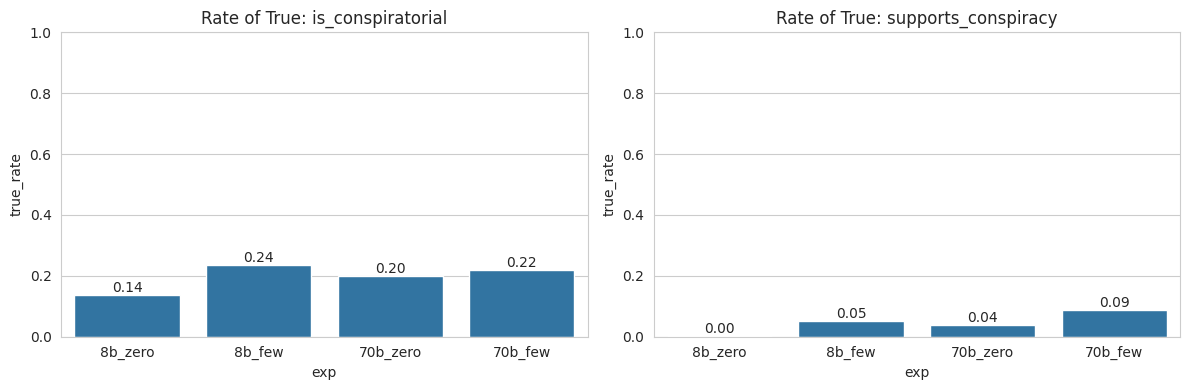

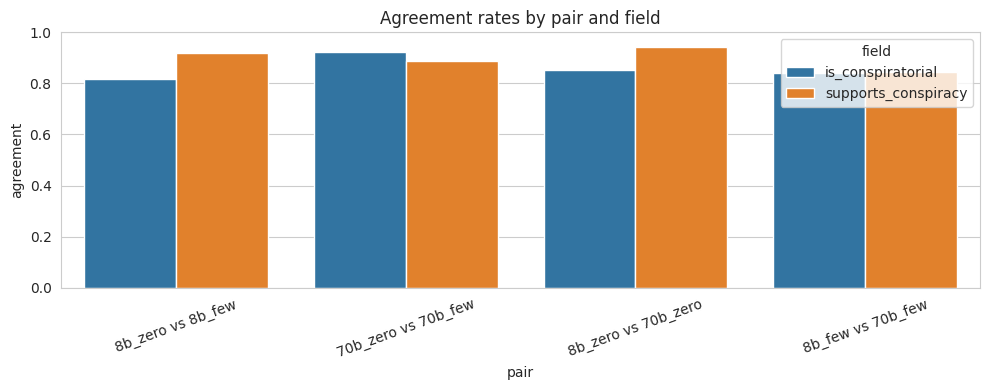

In [8]:
# Plots: class distributions
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax_idx, col in enumerate(['is_conspiratorial','supports_conspiracy']):
    ax = axes[ax_idx]
    plot_df = []
    for key, df in experiments.items():
        if col in df.columns:
            vc = df[col].value_counts()
            plot_df.append({'exp': key, 'true_rate': float(vc.get(True,0))/len(df)})
    plot_df = pd.DataFrame(plot_df)
    sns.barplot(data=plot_df, x='exp', y='true_rate', ax=ax)
    ax.set_title(f"Rate of True: {col}")
    ax.set_ylim(0,1)
    ax.bar_label(ax.containers[0], fmt='%.2f')
plt.tight_layout()
plt.show()

# Simple agreement bars between pairs
rows = []
for a,b in [('8b_zero','8b_few'),('70b_zero','70b_few'),('8b_zero','70b_zero'),('8b_few','70b_few')]:
    for col in ['is_conspiratorial','supports_conspiracy']:
        if col in experiments[a].columns and col in experiments[b].columns:
            rate, n = agreement_rate(experiments[a], experiments[b], col)
            rows.append({'pair': f'{a} vs {b}', 'field': col, 'agreement': rate})
plot_agree = pd.DataFrame(rows)
plt.figure(figsize=(10,4))
sns.barplot(data=plot_agree, x='pair', y='agreement', hue='field')
plt.ylim(0,1)
plt.title('Agreement rates by pair and field')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Findings (auto-generated)

- Is_conspiratorial / supports_conspiracy base rates are plotted above for each experiment.
- Agreement is shown for:
  - 8B zero vs few
  - 70B zero vs few
  - 8B vs 70B (zero-shot)
  - 8B vs 70B (few-shot)

Interpretation tips:
- Large gaps between zero-shot and few-shot within the same model suggest sensitivity to examples.
- Large gaps between 8B and 70B under the same prompting suggest model-size effects.
- If supports_conspiracy diverges more than is_conspiratorial, the model may be unstable on stance.

Next steps:
- Inspect disagreement cases by merging on `text_id` and listing rows where predictions differ.
- Evaluate span outputs in a follow-up notebook using the corresponding span CSVs.


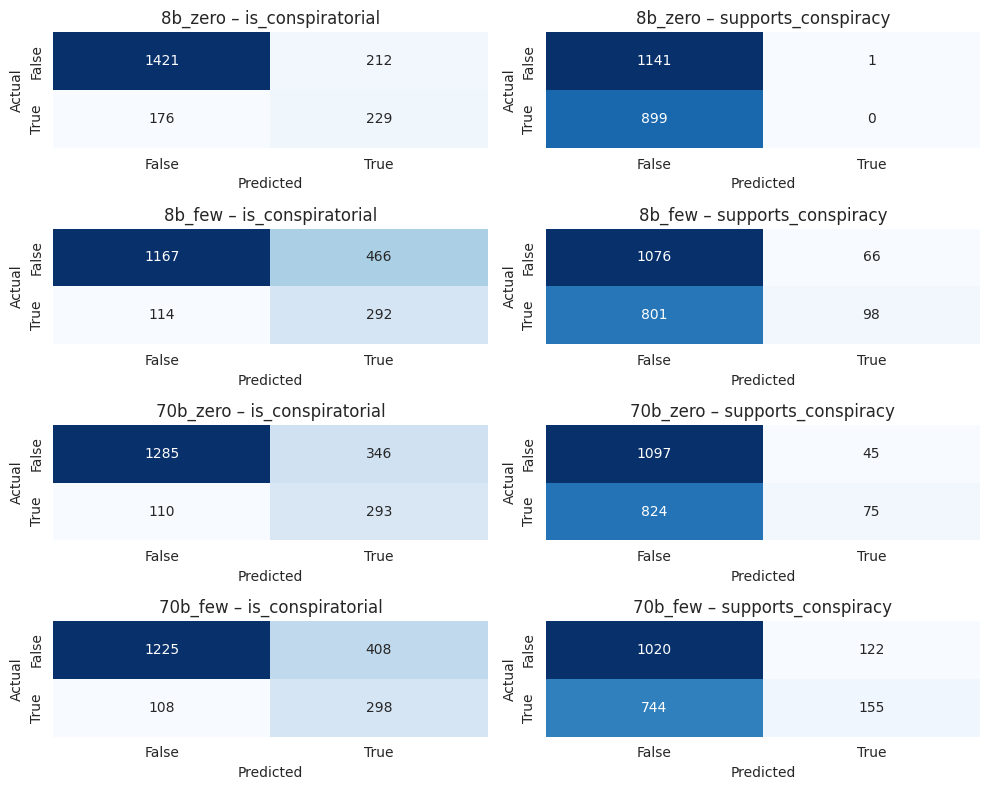

,experiment,task,accuracy,precision,recall,f1,n
6,70b_few,is_conspiratorial,0.746935,0.422096,0.733990,0.535971,2039
4,70b_zero,is_conspiratorial,0.775811,0.458529,0.727047,0.562380,2034
2,8b_few,is_conspiratorial,0.715547,0.385224,0.719212,0.501718,2039
0,8b_zero,is_conspiratorial,0.809617,0.519274,0.565432,0.541371,2038
7,70b_few,supports_conspiracy,0.575698,0.559567,0.172414,0.263605,2041
5,70b_zero,supports_conspiracy,0.574228,0.625000,0.083426,0.147203,2041
3,8b_few,supports_conspiracy,0.575208,0.597561,0.109010,0.184384,2041
1,8b_zero,supports_conspiracy,0.559040,0.000000,0.000000,0.000000,2041


accuracy                                    f1  \
task       is_conspiratorial supports_conspiracy is_conspiratorial   
experiment                                                           
70b_few                0.747               0.576             0.536   
70b_zero               0.776               0.574             0.562   
8b_few                 0.716               0.575             0.502   
8b_zero                0.810               0.559             0.541   

                                       precision                      \
task       supports_conspiracy is_conspiratorial supports_conspiracy   
experiment                                                             
70b_few                  0.264             0.422               0.560   
70b_zero                 0.147             0.459               0.625   
8b_few                   0.184             0.385               0.598   
8b_zero                  0.000             0.519               0.000   

                      recall                      
task       is_conspiratorial supports_conspiracy  
experiment                                        
70b_few                0.734               0.172  
70b_zero               0.727               0.083  
8b_few                 0.719               0.109  
8b_zero                0.565               0.000